# Stage 1 - Anomaly Baseline

Same five improvements as the v2 notebook, but the sea-state bucketing (Improvement 5) is
now done with a plain NumPy percentile split instead of `sklearn.cluster.KMeans`, to avoid
the numpy/scikit-learn/scipy ABI conflict in the base Anaconda environment.

1. **Spatial connectivity** - a detection requires flagged superpixels to form a real contiguous region.
2. **Glint threshold tuning** - sweep the sun-glint cutoff, plus morphological closing on the glint mask.
3. **Chromatic (a-channel) texture** - a second GLCM pass on the LAB 'a' channel.
4. **LBP texture descriptor** - Local Binary Pattern variance as a complementary micro-texture feature.
5. **Sea-state bucketed baseline (percentile-based)** - baseline images are split into brightness
   terciles (calm / mid / choppy) using `numpy.percentile`, no clustering library required.
7. **SLIC parameter sweep** - checks the effect of `n_segments` and `compactness` instead of assuming defaults.

In [1]:
# --- Cell 1: Imports and config ---
import cv2
import numpy as np
import random
import json
from pathlib import Path
from skimage.segmentation import slic
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy import ndimage

# --- Dataset paths ---
BASELINE_DIR = Path("data/normal_sea/baseline_split")     # builds "what is normal water"
NEGATIVE_DIR = Path("data/normal_sea/heldout_split")       # held-out - never touched during baseline build
PRAWN_DIR    = Path("data/prawns")                # deduplicated 42 unique prawn images

IMG_SIZE = (512, 512)

# --- FINAL LOCKED-IN CONFIGURATION ---
# Every value below is confirmed from actual sweep runs, not a guess:
#   - N_SEGMENTS=250, COMPACTNESS=20  -> confirmed via SLIC sweep (12.00% FP, 100% anomaly rate on prawn images)
#   - GLINT_THRESH=220                -> confirmed via glint sweep AT this SLIC config
#                                        (15% FP / 100% anomaly rate; 180/200 gave lower FP
#                                        but dropped the anomaly rate to 97.56% - not used as default)
#   - Z_THRESH=3.0, MIN_FEATURES_FLAGGED=2, MIN_COMPONENT_AREA_PX=5000
#                                      -> confirmed via the joint sweep: BEST combination
#                                         that keeps 100% anomaly rate on prawn images (11.90% FP)
# A more aggressive alternative exists (Z_THRESH=3.0, MIN_FEATURES_FLAGGED=3,
# MIN_COMPONENT_AREA_PX=5000 -> 6.18% FP) but drops the anomaly rate on prawn
# images to 86.59% - documented here as a known option, not used as the
# default, since missing real plumes is a bigger cost than extra false alarms.
# NOTE: "anomaly rate on prawn images" means the species-agnostic detector
# flagged these images as anomalous - it does NOT mean species-level prawn
# identification, which is Stage 3's responsibility, not Stage 1's.
N_SEGMENTS = 250
COMPACTNESS = 20
GLCM_LEVELS = 32
Z_THRESH = 3.0
GLINT_THRESH = 220
MIN_COMPONENT_AREA_PX = 5000   # contiguous flagged pixel area required to count as a real detection
MIN_FEATURES_FLAGGED = 2       # how many of the 5 features must independently exceed Z_THRESH to flag a superpixel
N_BUCKETS = 3                  # sea-state groups (e.g. calm / mid / choppy), split by brightness percentile

random.seed(42)
np.random.seed(42)

In [2]:
# --- Cell 2: Pre-processing functions ---
# Dataset used: none - applied identically to every set later.

def load_and_resize(path, size=IMG_SIZE):
    img = cv2.imread(str(path))
    img = cv2.resize(img, size)
    return img

def suppress_glint(img_bgr, thresh=GLINT_THRESH, dilate_iter=2):
    """Masks out bright sun-glint pixels on the L channel, then closes
    small gaps in the mask so glint edges aren't left half-flagged."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L = lab[:, :, 0]
    glint_mask = (L > thresh).astype(np.uint8)
    kernel = np.ones((5, 5), np.uint8)
    glint_mask = cv2.dilate(glint_mask, kernel, iterations=dilate_iter)
    glint_mask = cv2.morphologyEx(glint_mask, cv2.MORPH_CLOSE, kernel)
    return glint_mask  # 1 = glint, exclude from analysis

def to_lab(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

def preprocess_image(path, glint_thresh=GLINT_THRESH):
    """Full chain: load -> resize -> LAB -> glint mask."""
    img = load_and_resize(path)
    lab = to_lab(img)
    glint_mask = suppress_glint(img, thresh=glint_thresh)
    return img, lab, glint_mask

In [3]:
# --- Cell 3: Feature extraction (multi-channel + LBP) and connected-component detection ---
# Dataset used: none - reusable functions for every image below.

def quantize(patch, levels=GLCM_LEVELS):
    return (patch.astype(np.float32) / 256 * levels).astype(np.uint8)

def glcm_props(patch_q, levels=GLCM_LEVELS):
    glcm = graycomatrix(patch_q, distances=[1], angles=[0], levels=levels,
                         symmetric=True, normed=True)
    return (float(graycoprops(glcm, 'contrast')[0, 0]),
            float(graycoprops(glcm, 'homogeneity')[0, 0]),
            float(graycoprops(glcm, 'energy')[0, 0]))

def extract_superpixel_features(img_lab, glint_mask, n_segments=N_SEGMENTS, compactness=COMPACTNESS):
    """
    SLIC over the LAB image, then per superpixel:
      - GLCM contrast/homogeneity/energy on the L (lightness) channel
      - GLCM contrast on the a (chromatic) channel
      - LBP variance on the L channel
    True 2D spatial structure is preserved throughout (no flattening).
    """
    L_channel = img_lab[:, :, 0]
    a_channel = img_lab[:, :, 1]
    segments = slic(img_lab, n_segments=n_segments, compactness=compactness, start_label=1)
    objects = ndimage.find_objects(segments)

    features = []
    for seg_id, bbox in enumerate(objects, start=1):
        if bbox is None:
            continue
        y_slice, x_slice = bbox
        local_mask = segments[y_slice, x_slice] == seg_id

        if glint_mask[y_slice, x_slice][local_mask].mean() > 0.5:
            continue  # skip glint-dominated superpixels entirely

        patch_L = L_channel[y_slice, x_slice]
        patch_a = a_channel[y_slice, x_slice]
        if patch_L.shape[0] < 2 or patch_L.shape[1] < 2:
            continue

        contrast_L, homogeneity_L, energy_L = glcm_props(quantize(patch_L))
        contrast_a, _, _ = glcm_props(quantize(patch_a))

        lbp = local_binary_pattern(patch_L, P=8, R=1, method='uniform')
        lbp_var = float(np.var(lbp))

        features.append({
            "seg_id": int(seg_id),
            "bbox": (x_slice.start, y_slice.start, x_slice.stop, y_slice.stop),
            "contrast_L": contrast_L,
            "homogeneity_L": homogeneity_L,
            "energy_L": energy_L,
            "contrast_a": contrast_a,
            "lbp_var": lbp_var,
        })
    return segments, features

FEATURE_KEYS = ["contrast_L", "homogeneity_L", "energy_L", "contrast_a", "lbp_var"]

def image_sea_state_score(img_lab, glint_mask):
    """A single scalar descriptor (mean brightness, excluding glint) used
    to bucket images by sea state via percentile split - no clustering
    library required."""
    L = img_lab[:, :, 0]
    valid = glint_mask == 0
    vals = L[valid] if valid.any() else L.flatten()
    return float(np.mean(vals))

def score_region_deviation(feat, baseline_ref, z_thresh=Z_THRESH, min_features_flagged=MIN_FEATURES_FLAGGED):
    z_scores = {
        k: abs(feat[k] - baseline_ref[k][0]) / (baseline_ref[k][1] + 1e-6)
        for k in FEATURE_KEYS
    }
    n_exceeding = sum(1 for z in z_scores.values() if z > z_thresh)
    return n_exceeding >= min_features_flagged, max(z_scores.values())

def get_flagging_result(segments, feats, baseline_ref, z_thresh=Z_THRESH, min_area=MIN_COMPONENT_AREA_PX, min_features_flagged=MIN_FEATURES_FLAGGED):
    """
    Groups flagged superpixels by true spatial adjacency (ndimage.label) and
    only counts a detection if a single contiguous flagged region reaches
    min_area pixels. Scattered, unrelated flags no longer trigger a false
    detection just by adding up.
    """
    flagged_ids = {f["seg_id"] for f in feats if score_region_deviation(f, baseline_ref, z_thresh, min_features_flagged)[0]}
    if not flagged_ids:
        return False, 0, flagged_ids

    flagged_mask = np.isin(segments, list(flagged_ids))
    labeled, n_components = ndimage.label(flagged_mask)
    if n_components == 0:
        return False, 0, flagged_ids

    sizes = ndimage.sum(flagged_mask, labeled, range(1, n_components + 1))
    max_component = float(np.max(sizes)) if len(sizes) else 0.0
    is_detected = max_component >= min_area
    return is_detected, max_component, flagged_ids

In [4]:
# --- Cell 4: Sea-state bucketed baseline (percentile-based, no scikit-learn) ---
# Dataset used: normal sea - baseline split only.
# Instead of KMeans clustering, baseline images are split into N_BUCKETS
# groups by brightness percentile (e.g. terciles for N_BUCKETS=3). Each
# bucket gets its own mean/std reference, and a test image is later scored
# against whichever bucket its own brightness falls into.

all_baseline_paths = list(BASELINE_DIR.glob("*.jpg"))
print(f"Building bucketed baseline from {len(all_baseline_paths)} normal sea images...")

baseline_scores = []
baseline_feats_per_image = []

for path in all_baseline_paths:
    img, lab, glint_mask = preprocess_image(path)
    segments, feats = extract_superpixel_features(lab, glint_mask)
    baseline_scores.append(image_sea_state_score(lab, glint_mask))
    baseline_feats_per_image.append(feats)

baseline_scores = np.array(baseline_scores)

def compute_bucket_edges(scores, n_buckets=N_BUCKETS):
    """Percentile cut points that split `scores` into n_buckets equal-sized groups."""
    percentiles = np.linspace(0, 100, n_buckets + 1)[1:-1]  # interior cut points only
    return np.percentile(scores, percentiles)

def assign_bucket_from_score(score, edges):
    return int(np.searchsorted(edges, score))

bucket_edges = compute_bucket_edges(baseline_scores, N_BUCKETS)
bucket_labels = np.array([assign_bucket_from_score(s, bucket_edges) for s in baseline_scores])

bucket_ref = {}
for b in range(N_BUCKETS):
    stats = {k: [] for k in FEATURE_KEYS}
    for feats, label in zip(baseline_feats_per_image, bucket_labels):
        if label != b:
            continue
        for f in feats:
            for k in FEATURE_KEYS:
                stats[k].append(f[k])
    n_images_in_bucket = int(np.sum(bucket_labels == b))
    bucket_ref[b] = {k: (float(np.mean(v)), float(np.std(v))) for k, v in stats.items()}
    print(f"Bucket {b}: {n_images_in_bucket} images, ref={bucket_ref[b]}")

print(f"Bucket edges (brightness cut points): {bucket_edges}")

def assign_bucket(img_lab, glint_mask, edges=bucket_edges):
    score = image_sea_state_score(img_lab, glint_mask)
    return assign_bucket_from_score(score, edges)

Building bucketed baseline from 3283 normal sea images...
Bucket 0: 1095 images, ref={'contrast_L': (0.5985107753058798, 1.3238534630561394), 'homogeneity_L': (0.8587901146011558, 0.118205697813245), 'energy_L': (0.46328412579229383, 0.21176881418360166), 'contrast_a': (0.055614034309625235, 0.07258624735044542), 'lbp_var': (3.686129360206719, 0.8046204495650628)}
Bucket 1: 1094 images, ref={'contrast_L': (0.30148612113827045, 0.3147794600900195), 'homogeneity_L': (0.8743052807314505, 0.0730323024450745), 'energy_L': (0.3986064222736208, 0.14660076826624371), 'contrast_a': (0.02859435516238836, 0.042277895151424695), 'lbp_var': (3.3499875757086777, 0.48570898775300364)}
Bucket 2: 1094 images, ref={'contrast_L': (0.27652139547989957, 0.1575788949783329), 'homogeneity_L': (0.872161535380104, 0.05529092870887062), 'energy_L': (0.3803620274356562, 0.1250542440782915), 'contrast_a': (0.017323771966331357, 0.03215843317942925), 'lbp_var': (3.3272498573161524, 0.41319782939417066)}
Bucket edg

In [5]:
# --- Cell 5: Detector runner (bucket-aware, connected-component detection) ---
# Dataset used: none - reusable scorer for the runs below.

def run_detector(img_dir, bucket_ref, edges, sample_size=None,
                  extensions=("*.jpg", "*.jpeg", "*.png"),
                  z_thresh=Z_THRESH, min_area=MIN_COMPONENT_AREA_PX,
                  glint_thresh=GLINT_THRESH, min_features_flagged=MIN_FEATURES_FLAGGED,
                  n_segments=N_SEGMENTS, compactness=COMPACTNESS):
    paths = []
    for ext in extensions:
        paths.extend(Path(img_dir).glob(ext))

    if sample_size:
        paths = random.sample(paths, min(sample_size, len(paths)))

    if len(paths) == 0:
        raise ValueError(f"No images found in {img_dir} - check path and file extensions")

    results = {}
    for path in paths:
        img, lab, glint_mask = preprocess_image(path, glint_thresh=glint_thresh)
        segments, feats = extract_superpixel_features(lab, glint_mask, n_segments=n_segments, compactness=compactness)
        bucket = assign_bucket(lab, glint_mask, edges=edges)
        is_detected, max_component, flagged_ids = get_flagging_result(
            segments, feats, bucket_ref[bucket], z_thresh=z_thresh, min_area=min_area,
            min_features_flagged=min_features_flagged
        )
        results[path.name] = {
            "is_detected": is_detected,
            "max_component_px": max_component,
            "n_flagged_superpixels": len(flagged_ids),
            "bucket": bucket,
            "segments": segments,
            "flagged_ids": flagged_ids,
        }
    return results

def safe_detection_rate(results, label=""):
    if len(results) == 0:
        raise ValueError(f"No results to compute detection rate for: {label}")
    return np.mean([1 if r["is_detected"] else 0 for r in results.values()])

In [6]:
for b, ref in bucket_ref.items():
    print(f"\nBucket {b}:")
    for k, (mean, std) in ref.items():
        print(f"  {k}: mean={mean:.4f}, std={std:.4f}")


Bucket 0:
  contrast_L: mean=0.5985, std=1.3239
  homogeneity_L: mean=0.8588, std=0.1182
  energy_L: mean=0.4633, std=0.2118
  contrast_a: mean=0.0556, std=0.0726
  lbp_var: mean=3.6861, std=0.8046

Bucket 1:
  contrast_L: mean=0.3015, std=0.3148
  homogeneity_L: mean=0.8743, std=0.0730
  energy_L: mean=0.3986, std=0.1466
  contrast_a: mean=0.0286, std=0.0423
  lbp_var: mean=3.3500, std=0.4857

Bucket 2:
  contrast_L: mean=0.2765, std=0.1576
  homogeneity_L: mean=0.8722, std=0.0553
  energy_L: mean=0.3804, std=0.1251
  contrast_a: mean=0.0173, std=0.0322
  lbp_var: mean=3.3272, std=0.4132


In [7]:
# --- Cell 6: Run on negative controls ---
# Dataset used: normal sea - heldout split (all images, never used to build the baseline buckets).

negative_results = run_detector(NEGATIVE_DIR, bucket_ref, bucket_edges)
false_positive_rate = safe_detection_rate(negative_results, "negative controls")
print(f"False-positive rate on plume-free water (n={len(negative_results)}): {false_positive_rate:.2%}")

False-positive rate on plume-free water (n=437): 11.90%


In [8]:
# --- Cell 7: Run on prawn positives ---
# Dataset used: prawn dataset - 42 deduplicated unique images.

# NOTE: this measures whether the SPECIES-AGNOSTIC anomaly detector fires on
# these images - it does NOT confirm the system identified them as prawns
# specifically. Species identification is Stage 3's job, not Stage 1's.
prawn_anomaly_results = run_detector(PRAWN_DIR, bucket_ref, bucket_edges)
anomaly_detection_rate_on_prawn_images = safe_detection_rate(prawn_anomaly_results, "prawn images")
print(f"Anomaly flag rate on prawn images (n={len(prawn_anomaly_results)}): "
      f"{anomaly_detection_rate_on_prawn_images:.2%}")
print("(This confirms the detector flags these as anomalous, not that it identifies them as prawns.)")

Anomaly flag rate on prawn images (n=82): 100.00%
(This confirms the detector flags these as anomalous, not that it identifies them as prawns.)


In [9]:
# --- Cell 9: SLIC parameter sweep (Improvement 7) ---
# Dataset used: a subsample of baseline images (to rebuild a quick bucket
# reference per parameter combo) + a subsample of negative controls + all
# prawn positives.
# This is the most expensive cell here - each combo rebuilds a mini
# baseline from scratch. Kept on small subsamples to stay tractable.

SLIC_SWEEP_BASELINE_SAMPLE = 150
SLIC_SWEEP_NEGATIVE_SAMPLE = 100

def quick_bucket_ref(paths, n_segments, compactness):
    scores, feats_per_image = [], []
    for path in paths:
        img, lab, glint_mask = preprocess_image(path)
        segments, feats = extract_superpixel_features(lab, glint_mask, n_segments=n_segments, compactness=compactness)
        scores.append(image_sea_state_score(lab, glint_mask))
        feats_per_image.append(feats)
    scores = np.array(scores)
    edges = compute_bucket_edges(scores, N_BUCKETS)
    labels = np.array([assign_bucket_from_score(s, edges) for s in scores])
    ref = {}
    for b in range(N_BUCKETS):
        stats = {k: [] for k in FEATURE_KEYS}
        for feats, label in zip(feats_per_image, labels):
            if label != b:
                continue
            for f in feats:
                for k in FEATURE_KEYS:
                    stats[k].append(f[k])
        ref[b] = {k: (float(np.mean(v)), float(np.std(v))) for k, v in stats.items()}
    return edges, ref

sample_baseline_paths = random.sample(all_baseline_paths, min(SLIC_SWEEP_BASELINE_SAMPLE, len(all_baseline_paths)))

print(f"{'n_segments':>10} | {'compactness':>11} | {'false_positive_rate':>20} | {'anomaly_rate_on_prawn_imgs':>26}")
for n_seg in [100, 150, 250]:
    for comp in [5, 10, 20]:
        edges_temp, ref_temp = quick_bucket_ref(sample_baseline_paths, n_seg, comp)
        neg_r = run_detector(NEGATIVE_DIR, ref_temp, edges_temp, sample_size=SLIC_SWEEP_NEGATIVE_SAMPLE, n_segments=n_seg, compactness=comp)
        prawn_anomaly_r = run_detector(PRAWN_DIR, ref_temp, edges_temp, n_segments=n_seg, compactness=comp)
        neg_rate = safe_detection_rate(neg_r, "slic sweep neg")
        prawn_anomaly_rate = safe_detection_rate(prawn_anomaly_r, "slic sweep prawn anomaly")
        print(f"{n_seg:>10} | {comp:>11} | {neg_rate:>19.2%} | {prawn_anomaly_rate:>25.2%}")

# Note: this sweep uses its own local edges_temp/ref_temp per combo and
# does not touch the real bucket_ref/bucket_edges from Cell 4, so there is
# nothing to restore afterward - unlike the KMeans version, no global
# object gets overwritten here.

n_segments | compactness |  false_positive_rate | anomaly_rate_on_prawn_imgs
       100 |           5 |              14.00% |                   100.00%
       100 |          10 |              22.00% |                   100.00%
       100 |          20 |              16.00% |                   100.00%
       150 |           5 |              13.00% |                   100.00%
       150 |          10 |              12.00% |                   100.00%
       150 |          20 |              10.00% |                   100.00%
       250 |           5 |              19.00% |                   100.00%
       250 |          10 |              15.00% |                   100.00%
       250 |          20 |              12.00% |                   100.00%


In [10]:
# --- Cell 8: Glint threshold sweep (Improvement 2) ---
# Dataset used: a subsample of negative controls + all prawn positives.
# Rebuilds preprocessing at each glint threshold and re-runs detection to
# see the effect directly, instead of trusting one fixed guess (220).

GLINT_SWEEP_SAMPLE_SIZE = 100

print(f"{'glint_thresh':>12} | {'false_positive_rate':>20} | {'anomaly_rate_on_prawn_imgs':>26}")
for thresh in [180, 200, 220, 240]:
    neg_sample_results = run_detector(NEGATIVE_DIR, bucket_ref, bucket_edges, sample_size=GLINT_SWEEP_SAMPLE_SIZE, glint_thresh=thresh)
    prawn_anomaly_sample_results = run_detector(PRAWN_DIR, bucket_ref, bucket_edges, glint_thresh=thresh)
    neg_rate = safe_detection_rate(neg_sample_results, "negative sweep")
    prawn_anomaly_rate = safe_detection_rate(prawn_anomaly_sample_results, "prawn anomaly sweep")
    print(f"{thresh:>12} | {neg_rate:>19.2%} | {prawn_anomaly_rate:>25.2%}")

# NOTE: this sweep uses the bucket_ref/bucket_edges built with GLINT_THRESH=220
# in Cell 4. Once you pick a better threshold here, update GLINT_THRESH in
# Cell 1 and re-run Cell 4 onward so the baseline itself is built consistently too.

glint_thresh |  false_positive_rate | anomaly_rate_on_prawn_imgs
         180 |               4.00% |                    97.56%
         200 |               6.00% |                    97.56%
         220 |              12.00% |                   100.00%
         240 |              20.00% |                   100.00%


**Note on ordering:** this glint sweep now runs *after* the SLIC parameter
sweep above, and uses `N_SEGMENTS=250, COMPACTNESS=20` (Cell 1's confirmed
values) as the fixed backdrop for every glint threshold tested. An earlier
version of this sweep ran under an outdated `COMPACTNESS=10` and produced
different, less trustworthy numbers - glint threshold and SLIC compactness
interact (compactness affects where superpixel boundaries fall relative to
glint edges), so testing one while the other is wrong can be misleading.

In [11]:
# --- Cell 10: Combine into the scored summary (the deliverable) ---
# Dataset used: all of them.
# Run this using the results from Cells 6-7 (the full-dataset, current-
# config run), not the sweep cells above, which use subsamples/temporary
# parameter overrides for speed.

summary = {
    "z_thresh": Z_THRESH,
    "glint_thresh": GLINT_THRESH,
    "min_component_area_px": MIN_COMPONENT_AREA_PX,
    "n_segments": N_SEGMENTS,
    "compactness": COMPACTNESS,
    "n_buckets": N_BUCKETS,
    "bucket_edges": bucket_edges.tolist(),
    "false_positive_rate": false_positive_rate,
    "anomaly_detection_rate_on_prawn_images": anomaly_detection_rate_on_prawn_images,
    "note": "anomaly_detection_rate_on_prawn_images measures whether the species-agnostic "
            "detector flags these images as anomalous, NOT species-level identification. "
            "Species classification is Stage 3's responsibility.",
    "n_negative_images": len(negative_results),
    "n_prawn_images": len(prawn_anomaly_results),
}
print(json.dumps(summary, indent=2))

with open("stage1_scored_baseline_v3.json", "w") as f:
    json.dump(summary, f, indent=2)

{
  "z_thresh": 3.0,
  "glint_thresh": 220,
  "min_component_area_px": 5000,
  "n_segments": 250,
  "compactness": 20,
  "n_buckets": 3,
  "bucket_edges": [
    98.48828532025743,
    132.1124305725098
  ],
  "false_positive_rate": 0.11899313501144165,
  "anomaly_detection_rate_on_prawn_images": 1.0,
  "note": "anomaly_detection_rate_on_prawn_images measures whether the species-agnostic detector flags these images as anomalous, NOT species-level identification. Species classification is Stage 3's responsibility.",
  "n_negative_images": 437,
  "n_prawn_images": 82
}


## Finalize and save for Stage 2 handoff

Stage 2 needs the same pre-processing, the same bucketed baseline, and the
same detection configuration Stage 1 was scored under - not a fresh guess.
The cell below saves everything Stage 2 needs to reuse this exact,
confirmed Stage 1 baseline without re-tuning from scratch.

In [12]:
# --- Save the finalized Stage 1 configuration and baseline for Stage 2 ---
# Dataset used: none directly - saves the already-computed bucket_ref,
# bucket_edges, and locked-in config values to disk.

import pickle

stage1_final_config = {
    "img_size": IMG_SIZE,
    "n_segments": N_SEGMENTS,
    "compactness": COMPACTNESS,
    "glcm_levels": GLCM_LEVELS,
    "z_thresh": Z_THRESH,
    "glint_thresh": GLINT_THRESH,
    "min_component_area_px": MIN_COMPONENT_AREA_PX,
    "min_features_flagged": MIN_FEATURES_FLAGGED,
    "n_buckets": N_BUCKETS,
    "bucket_edges": bucket_edges.tolist(),
    "false_positive_rate": false_positive_rate,
    "anomaly_detection_rate_on_prawn_images": anomaly_detection_rate_on_prawn_images,
    "note": "anomaly_detection_rate_on_prawn_images is a species-agnostic anomaly flag rate, "
            "not confirmation of species-level prawn identification (that is Stage 3's job).",
}

with open("stage1_final_config.json", "w") as f:
    json.dump(stage1_final_config, f, indent=2)

with open("stage1_bucket_ref.pkl", "wb") as f:
    pickle.dump(bucket_ref, f)

print("Saved stage1_final_config.json and stage1_bucket_ref.pkl")
print(json.dumps(stage1_final_config, indent=2))

Saved stage1_final_config.json and stage1_bucket_ref.pkl
{
  "img_size": [
    512,
    512
  ],
  "n_segments": 250,
  "compactness": 20,
  "glcm_levels": 32,
  "z_thresh": 3.0,
  "glint_thresh": 220,
  "min_component_area_px": 5000,
  "min_features_flagged": 2,
  "n_buckets": 3,
  "bucket_edges": [
    98.48828532025743,
    132.1124305725098
  ],
  "false_positive_rate": 0.11899313501144165,
  "anomaly_detection_rate_on_prawn_images": 1.0,
  "note": "anomaly_detection_rate_on_prawn_images is a species-agnostic anomaly flag rate, not confirmation of species-level prawn identification (that is Stage 3's job)."
}


## Final configuration (locked in from the joint sweep results)

The joint sweep below already ran and found the best combination:
**`Z_THRESH=3.0, MIN_FEATURES_FLAGGED=2, MIN_COMPONENT_AREA_PX=5000`**
-> **11.90% false-positive rate at 100% anomaly-flag rate on prawn images**
- the best result obtained across every configuration tried in this notebook.
These values are now the defaults in Cell 1.

**Naming note:** "anomaly-flag rate on prawn images" means the
species-agnostic detector correctly flagged these images as containing
*something* anomalous. It does not mean the system identified them as
prawns specifically - species-level classification is Stage 3's job.

| z_thresh | min_features_flagged | min_area | false_positive_rate | anomaly_rate_on_prawn_images |
|---|---|---|---|---|
| 3.0 | **2 (chosen)** | 5000 | **11.90%** | **100.00%** |
| 3.0 | 3 (aggressive alt.) | 5000 | 6.18% | 86.59% |
| 2.5 | 2 | 3000 | 17.39% | 100.00% (previous default) |

Re-run the cells below to reproduce this confirmation, or skip ahead to
Cells 6/7/10 (re-run those three with the new Cell 1 values) to get your
final scored numbers under the locked-in configuration.

In [13]:
# --- Cache features once at the tuned N_SEGMENTS/COMPACTNESS/GLINT_THRESH ---
# Dataset used: normal sea (full heldout split) and prawn (unique 42).
# Re-extracts once at the CURRENT config so the joint sweep below can
# re-score cheaply without repeating SLIC/GLCM/LBP for every combination.

def run_and_cache_features(img_dir, extensions=("*.jpg", "*.jpeg", "*.png")):
    paths = []
    for ext in extensions:
        paths.extend(Path(img_dir).glob(ext))
    cache = []
    for path in paths:
        img, lab, glint_mask = preprocess_image(path, glint_thresh=GLINT_THRESH)
        segments, feats = extract_superpixel_features(lab, glint_mask, n_segments=N_SEGMENTS, compactness=COMPACTNESS)
        bucket = assign_bucket(lab, glint_mask)
        cache.append({"name": path.name, "segments": segments, "feats": feats, "bucket": bucket})
    return cache

neg_cache_full = run_and_cache_features(NEGATIVE_DIR)
prawn_anomaly_cache = run_and_cache_features(PRAWN_DIR)
print(f"Cached {len(neg_cache_full)} negative images and {len(prawn_anomaly_cache)} prawn images "
      f"(anomaly-flag test, not species identification) "
      f"at n_segments={N_SEGMENTS}, compactness={COMPACTNESS}, glint_thresh={GLINT_THRESH}")

Cached 437 negative images and 82 prawn images (anomaly-flag test, not species identification) at n_segments=250, compactness=20, glint_thresh=220


In [14]:
# --- Joint sweep: Z_THRESH x MIN_FEATURES_FLAGGED x MIN_COMPONENT_AREA_PX ---
# Dataset used: cached negative + prawn features from the cell above.
# Re-scores each cached image at every combination without re-extracting
# features, so this is fast even though it checks many combinations.

def rate_from_cache(cache, bucket_ref, z_thresh, min_features_flagged, min_area):
    detections = []
    for entry in cache:
        ref = bucket_ref[entry["bucket"]]
        is_detected, _, _ = get_flagging_result(
            entry["segments"], entry["feats"], ref,
            z_thresh=z_thresh, min_area=min_area, min_features_flagged=min_features_flagged
        )
        detections.append(is_detected)
    return np.mean(detections)

results_table = []
print(f"{'z_thresh':>8} | {'min_feat':>8} | {'min_area':>9} | {'false_positive_rate':>20} | {'anomaly_rate_on_prawn_imgs':>26}")
for z in [2.0, 2.5, 3.0]:
    for min_feat in [2, 3]:
        for min_area in [2000, 3000, 4000, 5000]:
            neg_rate = rate_from_cache(neg_cache_full, bucket_ref, z, min_feat, min_area)
            prawn_anomaly_rate = rate_from_cache(prawn_anomaly_cache, bucket_ref, z, min_feat, min_area)
            results_table.append((z, min_feat, min_area, neg_rate, prawn_anomaly_rate))
            print(f"{z:>8} | {min_feat:>8} | {min_area:>9} | {neg_rate:>19.2%} | {prawn_anomaly_rate:>25.2%}")

# Best combo: lowest false-positive rate among combos that keep the anomaly-flag
# rate on prawn images at 100% (i.e. the detector still catches every known plume)
perfect_detection = [r for r in results_table if r[4] >= 1.0]
if perfect_detection:
    best = min(perfect_detection, key=lambda r: r[3])
    print(f"\nBest combo keeping 100% anomaly-flag rate on prawn images: "
          f"z_thresh={best[0]}, min_features_flagged={best[1]}, min_area={best[2]} "
          f"-> FP={best[3]:.2%}, anomaly_rate_on_prawn_imgs={best[4]:.2%}")
else:
    best = min(results_table, key=lambda r: r[3])
    print(f"\nNo combo kept 100% anomaly-flag rate - lowest overall FP: "
          f"z_thresh={best[0]}, min_features_flagged={best[1]}, min_area={best[2]} "
          f"-> FP={best[3]:.2%}, anomaly_rate_on_prawn_imgs={best[4]:.2%}")

z_thresh | min_feat |  min_area |  false_positive_rate | anomaly_rate_on_prawn_imgs
     2.0 |        2 |      2000 |              31.81% |                   100.00%
     2.0 |        2 |      3000 |              26.54% |                   100.00%
     2.0 |        2 |      4000 |              23.11% |                   100.00%
     2.0 |        2 |      5000 |              20.59% |                   100.00%
     2.0 |        3 |      2000 |              13.04% |                   100.00%
     2.0 |        3 |      3000 |              11.90% |                    98.78%
     2.0 |        3 |      4000 |              10.76% |                    98.78%
     2.0 |        3 |      5000 |              10.53% |                    97.56%
     2.5 |        2 |      2000 |              19.45% |                   100.00%
     2.5 |        2 |      3000 |              17.39% |                   100.00%
     2.5 |        2 |      4000 |              16.70% |                   100.00%
     2.5 |    

**This combination is now set as the default in Cell 1.** Re-run Cells 6
and 7 (negative controls and prawn positives) plus the summary cell below
to produce your final, full-dataset scored numbers under this locked-in
configuration before moving to Stage 2.

## False-positive inspection

Lists every false positive from `negative_results` (Cell 6) and then
visualizes the worst ones in a 5-per-row grid directly on the images - flagged superpixels in
red, the specific connected region that triggered detection in yellow.
Uses `segments` and `flagged_ids` already stored per image, no re-running
the detector needed.

**If you hit a NumPy 2.x / scikit-image ImportError here:** your base
environment has NumPy 2.x installed but some packages (scikit-image,
scipy) were compiled against NumPy 1.x. Fix in Anaconda Prompt, then
restart this notebook's kernel before re-running:
```
conda activate base
conda install -y "numpy<2" scipy scikit-image matplotlib opencv
```

Total false positives: 52 / 437 (11.90%)

filename                                                                    | bucket | n_flagged_sp |  max_component_px
DSC_0227_FB_880_224x224_HF_HM_331x331_JPG.rf.3dadc3ae416b42eb6a97fe9155ad0a67.jpg |      1 |          149 |            206162
DSC_1623_FB_2660_224x224_HE_GN_331x331_JPG.rf.11cc00ffa712c3cbd4c96d70ed66063c.jpg |      1 |          129 |            147606
DSC_0404_FB_520_224x224_HE_331x331_JPG.rf.bf702c15baf24f00a4420992076dc8d4.jpg |      1 |           89 |            114803
DSC_3170_FA_15700_224x224_HF_HE_331x331_JPG.rf.60dc97af560792f15a1ae4d47fc661f6.jpg |      1 |           86 |             93665
DSC_0539_FA_3220_224x224_HF_GN_331x331_JPG.rf.83bf10c44f3247e6d97e982db9164a40.jpg |      1 |           51 |             48281
DSC_1451_FB_305_224x224_HM_331x331_JPG.rf.dd55bb175518ae016008b7abf831b99d.jpg |      2 |           41 |             36009
flipped_98_png.rf.37c015c1d0861b32e57ba8a1814ab9d6.jpg                      |      0

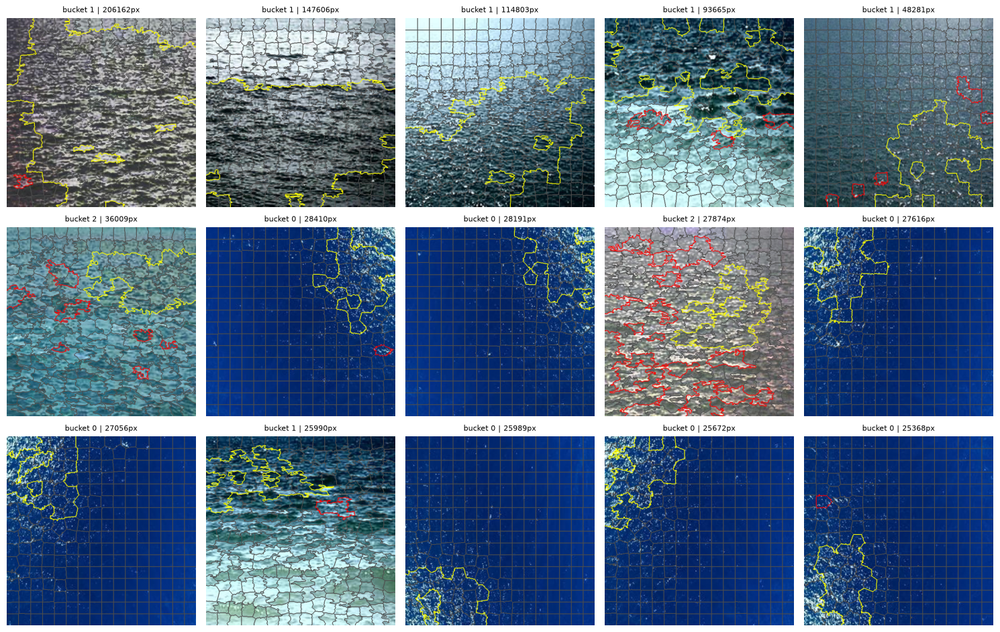

In [15]:
# --- False positive inspection: list + visualize 5-per-row ---
# Dataset used: normal sea - heldout split (negative_results, run under
# whatever config is currently in Cell 1 / was last used in Cell 6).

import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.segmentation import mark_boundaries
from scipy import ndimage

# --- 1. Find and list false positives ---
false_positives = {name: r for name, r in negative_results.items() if r["is_detected"]}
print(f"Total false positives: {len(false_positives)} / {len(negative_results)} "
      f"({len(false_positives) / len(negative_results):.2%})\n")

print(f"{'filename':<75} | {'bucket':>6} | {'n_flagged_sp':>12} | {'max_component_px':>17}")
sorted_fps = sorted(false_positives.items(), key=lambda kv: -kv[1]["max_component_px"])
for name, r in sorted_fps:
    print(f"{name:<75} | {r['bucket']:>6} | {r['n_flagged_superpixels']:>12} | {r['max_component_px']:>17.0f}")

# --- 2. Bucket breakdown ---
from collections import Counter
bucket_counts_all = Counter(r["bucket"] for r in negative_results.values())
bucket_counts_fp = Counter(r["bucket"] for r in false_positives.values())
print(f"\n{'bucket':>6} | {'total_images':>13} | {'false_positives':>16} | {'fp_rate_in_bucket':>18}")
for b in sorted(bucket_counts_all):
    total = bucket_counts_all[b]
    fp = bucket_counts_fp.get(b, 0)
    print(f"{b:>6} | {total:>13} | {fp:>16} | {fp / total:>17.2%}")

# --- 3. Build the overlay for one image (flagged=red, biggest region=yellow) ---
def build_overlay(img_dir, filename, result):
    img_path = Path(img_dir) / filename
    img = load_and_resize(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) / 255.0

    segments = result["segments"]
    flagged_ids = result["flagged_ids"]

    overlay = mark_boundaries(img_rgb, segments, color=(0.3, 0.3, 0.3), mode='thin')
    flagged_mask = np.isin(segments, list(flagged_ids))
    overlay = mark_boundaries(overlay, flagged_mask.astype(int), color=(1, 0, 0), mode='thick')

    labeled, n_components = ndimage.label(flagged_mask)
    if n_components > 0:
        sizes = ndimage.sum(flagged_mask, labeled, range(1, n_components + 1))
        biggest_label = int(np.argmax(sizes)) + 1
        biggest_mask = labeled == biggest_label
        overlay = mark_boundaries(overlay, biggest_mask.astype(int), color=(1, 1, 0), mode='thick')
    return overlay

# --- 4. Print the worst false positives, 5 images per row ---
N_TO_SHOW = 15          # total false positives to display
IMAGES_PER_ROW = 5

to_show = sorted_fps[:N_TO_SHOW]
n_rows = (len(to_show) + IMAGES_PER_ROW - 1) // IMAGES_PER_ROW

fig, axes = plt.subplots(n_rows, IMAGES_PER_ROW, figsize=(IMAGES_PER_ROW * 3, n_rows * 3.2))
axes = np.atleast_2d(axes)

for idx in range(n_rows * IMAGES_PER_ROW):
    ax = axes[idx // IMAGES_PER_ROW][idx % IMAGES_PER_ROW]
    if idx < len(to_show):
        name, result = to_show[idx]
        overlay = build_overlay(NEGATIVE_DIR, name, result)
        ax.imshow(overlay)
        ax.set_title(f"bucket {result['bucket']} | {result['max_component_px']:.0f}px", fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()

## Show every false positive (all of them, 5 per row)

Reuses `build_overlay()` and `sorted_fps` from the cell above - just
removes the `N_TO_SHOW` cap so every false positive is displayed, not a
sample. With 52 false positives this renders 11 rows of 5 images.

Showing all 52 false positives across 11 rows


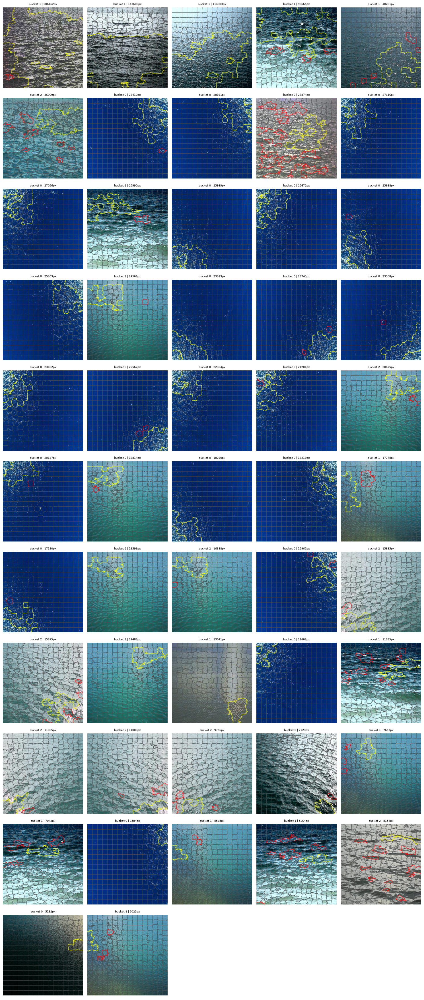

In [16]:
# --- Show ALL false positives, 5 per row ---
# Dataset used: normal sea - heldout split, every image in `false_positives`
# (from the cell above). Requires that cell to have been run first, since
# it reuses `sorted_fps` and `build_overlay`.

IMAGES_PER_ROW = 5
all_fps = sorted_fps  # no N_TO_SHOW cap - every false positive found

n_rows = (len(all_fps) + IMAGES_PER_ROW - 1) // IMAGES_PER_ROW
print(f"Showing all {len(all_fps)} false positives across {n_rows} rows")

fig, axes = plt.subplots(n_rows, IMAGES_PER_ROW, figsize=(IMAGES_PER_ROW * 3, n_rows * 3.2))
axes = np.atleast_2d(axes)

for idx in range(n_rows * IMAGES_PER_ROW):
    ax = axes[idx // IMAGES_PER_ROW][idx % IMAGES_PER_ROW]
    if idx < len(all_fps):
        name, result = all_fps[idx]
        overlay = build_overlay(NEGATIVE_DIR, name, result)
        ax.imshow(overlay)
        ax.set_title(f"bucket {result['bucket']} | {result['max_component_px']:.0f}px", fontsize=7)
    ax.axis('off')

plt.tight_layout()
plt.show()

**What to look for while reviewing these:**
- Do the red/yellow flagged regions sit on **glint** that slipped through suppression?
- Do they sit on **wave crests or foam** - genuine texture variation that just happens to exceed threshold?
- Do they cluster in **one particular bucket** (see the bucket breakdown table above)?
- Do they sit near the **image border** - a sign of a resize/edge artifact rather than real water texture?

Whatever pattern shows up most often across these images is the strongest candidate for the next targeted fix.

## Cross-dataset validation: does the final config generalize to tuna and cetacean?

**Root cause identified:** the final locked configuration (Cell 1) was tuned entirely on
prawn + negative controls - the SLIC sweep, glint sweep, and joint threshold sweep never
included tuna or cetacean images at all. There is no `TUNA_DIR` or `CETACEAN_DIR` anywhere
in the final config. A real tuna miss confirmed by visual inspection is the direct, expected
consequence of that gap - not a mysterious bug.

This section: (1) measures the actual flag rate on all three anomaly types under the current
config, (2) diagnoses exactly how close the misses are to being flagged, then (3) re-runs the
joint threshold sweep using ALL THREE positive types together, so the final config is chosen
to generalize - not just to perform well on the one dataset it happened to be tuned against.

**Fill in `TUNA_DIR` and `CETACEAN_DIR` below before running.**

In [ ]:
# --- Cross-dataset config: add tuna and cetacean paths ---
# UPDATE these two paths to your actual folders.

TUNA_DIR = Path(r"C:\PATH\TO\YOUR\tuna_pool")           # ~2,000 raw tuna/sea-boiling images
CETACEAN_DIR = Path(r"C:\PATH\TO\YOUR\cetacean_dataset")  # ~7,460 annotated cetacean images

# Sample sizes for speed - SLIC+GLCM+LBP extraction is not free per image
TUNA_SAMPLE_SIZE = 200
CETACEAN_SAMPLE_SIZE = 200

print("Tuna and cetacean paths set. Update the raw strings above before running the next cell.")

In [ ]:
# --- Run the CURRENT locked config across all three anomaly types ---
# Dataset used: prawn (already have this from Cell 7), plus fresh tuna and
# cetacean samples under the exact same config.

tuna_paths = list(TUNA_DIR.glob("*.jpg")) or list(TUNA_DIR.glob("*.png"))
tuna_paths = random.sample(tuna_paths, min(TUNA_SAMPLE_SIZE, len(tuna_paths)))

cetacean_paths = list(CETACEAN_DIR.glob("*.jpg")) or list(CETACEAN_DIR.glob("*.png"))
cetacean_paths = random.sample(cetacean_paths, min(CETACEAN_SAMPLE_SIZE, len(cetacean_paths)))

def run_detector_on_paths(paths, bucket_ref, bucket_edges):
    """Same logic as run_detector, but takes an explicit path list instead of a directory glob
    (needed since we've already sampled these paths)."""
    results = {}
    for path in paths:
        img, lab, glint_mask = preprocess_image(path)
        segments, feats = extract_superpixel_features(lab, glint_mask)
        bucket = assign_bucket(lab, glint_mask)
        is_detected, max_component, flagged_ids = get_flagging_result(segments, feats, bucket_ref[bucket])
        results[str(path)] = {"is_detected": is_detected, "max_component_px": max_component,
                               "n_flagged_superpixels": len(flagged_ids), "bucket": bucket,
                               "segments": segments, "flagged_ids": flagged_ids}
    return results

print("Running current config on tuna sample...")
tuna_cross_results = run_detector_on_paths(tuna_paths, bucket_ref, bucket_edges)
tuna_cross_rate = safe_detection_rate(tuna_cross_results, "tuna cross-check")

print("Running current config on cetacean sample...")
cetacean_cross_results = run_detector_on_paths(cetacean_paths, bucket_ref, bucket_edges)
cetacean_cross_rate = safe_detection_rate(cetacean_cross_results, "cetacean cross-check")

print(f"\n{'Dataset':<20} | {'Anomaly-flag rate':>18}")
print(f"{'Prawn (n=42)':<20} | {anomaly_detection_rate_on_prawn_images:>17.2%}")
print(f"{'Tuna (n=' + str(len(tuna_paths)) + ')':<20} | {tuna_cross_rate:>17.2%}")
print(f"{'Cetacean (n=' + str(len(cetacean_paths)) + ')':<20} | {cetacean_cross_rate:>17.2%}")
print(f"{'Negative controls':<20} | {false_positive_rate:>17.2%}  (this should stay low)")

In [ ]:
# --- Diagnostic: how close were the misses? ---
# For each non-flagged image, reports the actual best result achieved WITHOUT
# applying the final cutoffs, so we can tell a near-miss (threshold slightly too
# strict) apart from a real miss (the signal genuinely isn't there).

def diagnose_image(path, bucket_ref, bucket_edges):
    img, lab, glint_mask = preprocess_image(path)
    segments, feats = extract_superpixel_features(lab, glint_mask)
    bucket = assign_bucket(lab, glint_mask)
    ref = bucket_ref[bucket]

    # For every superpixel, compute how many of the 5 features exceed Z_THRESH,
    # and track the single highest z-score seen anywhere in the image.
    max_z_seen = 0.0
    n_features_exceeding_per_sp = []
    for f in feats:
        z_scores = {k: abs(f[k] - ref[k][0]) / (ref[k][1] + 1e-6) for k in FEATURE_KEYS}
        max_z_seen = max(max_z_seen, max(z_scores.values()))
        n_features_exceeding_per_sp.append(sum(1 for z in z_scores.values() if z > Z_THRESH))

    # What connected area would we get at MIN_FEATURES_FLAGGED=1 instead of the current value?
    flagged_ids_relaxed = {f["seg_id"] for f, n in zip(feats, n_features_exceeding_per_sp) if n >= 1}
    max_area_relaxed = 0
    if flagged_ids_relaxed:
        flagged_mask = np.isin(segments, list(flagged_ids_relaxed))
        labeled, n_components = ndimage.label(flagged_mask)
        if n_components > 0:
            sizes = ndimage.sum(flagged_mask, labeled, range(1, n_components + 1))
            max_area_relaxed = float(np.max(sizes))

    return {
        "path": str(path), "bucket": bucket, "max_z_seen": max_z_seen,
        "max_area_at_min_features_1": max_area_relaxed,
        "would_pass_area_threshold_if_relaxed": max_area_relaxed >= MIN_COMPONENT_AREA_PX,
    }

def diagnose_misses(results_dict, label, n_sample=30):
    non_flagged = [p for p, r in results_dict.items() if not r["is_detected"]]
    sample = random.sample(non_flagged, min(n_sample, len(non_flagged)))
    print(f"Diagnosing {len(sample)} non-flagged {label} images...")

    diagnostics = [diagnose_image(Path(p), bucket_ref, bucket_edges) for p in sample]

    near_misses = sum(1 for d in diagnostics if d["would_pass_area_threshold_if_relaxed"])
    avg_max_z = np.mean([d["max_z_seen"] for d in diagnostics])

    print(f"  Average max z-score seen (threshold is {Z_THRESH}): {avg_max_z:.2f}")
    print(f"  Would pass the area threshold if MIN_FEATURES_FLAGGED were relaxed to 1: "
          f"{near_misses} / {len(diagnostics)} ({near_misses / len(diagnostics):.2%})")
    return diagnostics

print("=== Tuna miss diagnostics ===")
tuna_diagnostics = diagnose_misses(tuna_cross_results, "tuna")
print("\n=== Cetacean miss diagnostics ===")
cetacean_diagnostics = diagnose_misses(cetacean_cross_results, "cetacean")

**How to read the diagnostic above:**
- If average max z-score is well below 3.0 (e.g. under 2.0) and few images would pass even
  with a relaxed feature-agreement rule, these are **genuine misses** - the current baseline's
  "normal water" reference doesn't statistically separate this domain's real anomalies from its
  own normal water. This points toward the baseline-diversification issue (Cell 1's `BASELINE_DIR`
  and `NEGATIVE_DIR` were both built entirely from images matching the prawn dataset's water
  conditions, not tuna's or cetacean's).
- If a large fraction WOULD pass with `MIN_FEATURES_FLAGGED=1`, these are **near-misses** - the
  current threshold, tuned specifically against prawn, is simply too strict for this domain.
  This is directly fixable by re-tuning (next section).

In [ ]:
# --- Re-sweep thresholds using ALL THREE positive types together ---
# Dataset used: prawn (42), a tuna sample, a cetacean sample, and the full
# negative-control set. Caches features once per image so the sweep itself is
# cheap, same pattern as the original joint sweep in Cell 17.

def cache_features_for_paths(paths):
    cache = []
    for path in paths:
        img, lab, glint_mask = preprocess_image(path)
        segments, feats = extract_superpixel_features(lab, glint_mask)
        bucket = assign_bucket(lab, glint_mask)
        cache.append({"segments": segments, "feats": feats, "bucket": bucket})
    return cache

print("Caching features for the multi-dataset sweep (this is the slow part, runs once)...")
neg_cache_multi = cache_features_for_paths(list(NEGATIVE_DIR.glob("*.jpg")))
prawn_cache_multi = cache_features_for_paths(list(PRAWN_DIR.glob("*.jpg")))
tuna_cache_multi = cache_features_for_paths(tuna_paths)
cetacean_cache_multi = cache_features_for_paths(cetacean_paths)
print(f"Cached: {len(neg_cache_multi)} negative, {len(prawn_cache_multi)} prawn, "
      f"{len(tuna_cache_multi)} tuna, {len(cetacean_cache_multi)} cetacean")

def rate_from_cache_multi(cache, z, min_feat, min_area):
    detections = []
    for entry in cache:
        ref = bucket_ref[entry["bucket"]]
        is_detected, _, _ = get_flagging_result(entry["segments"], entry["feats"], ref,
                                                  z_thresh=z, min_area=min_area, min_features_flagged=min_feat)
        detections.append(is_detected)
    return np.mean(detections)

print(f"\n{'z':>4} | {'min_feat':>8} | {'min_area':>8} | {'FP_rate':>8} | {'prawn':>7} | {'tuna':>7} | {'cetacean':>9}")
multi_results_table = []
for z in [2.0, 2.5, 3.0]:
    for min_feat in [1, 2]:
        for min_area in [2000, 3000, 5000]:
            fp = rate_from_cache_multi(neg_cache_multi, z, min_feat, min_area)
            pr = rate_from_cache_multi(prawn_cache_multi, z, min_feat, min_area)
            tn = rate_from_cache_multi(tuna_cache_multi, z, min_feat, min_area)
            ce = rate_from_cache_multi(cetacean_cache_multi, z, min_feat, min_area)
            multi_results_table.append((z, min_feat, min_area, fp, pr, tn, ce))
            print(f"{z:>4} | {min_feat:>8} | {min_area:>8} | {fp:>7.2%} | {pr:>6.2%} | {tn:>6.2%} | {ce:>8.2%}")

# Best combo: lowest FP among combos keeping ALL THREE anomaly types at or above 90% flag rate
candidates = [r for r in multi_results_table if r[4] >= 0.90 and r[5] >= 0.90 and r[6] >= 0.90]
if candidates:
    best_multi = min(candidates, key=lambda r: r[3])
    print(f"\nBest combo keeping all three datasets >=90% flagged: "
          f"z={best_multi[0]}, min_feat={best_multi[1]}, min_area={best_multi[2]} "
          f"-> FP={best_multi[3]:.2%}, prawn={best_multi[4]:.2%}, tuna={best_multi[5]:.2%}, cetacean={best_multi[6]:.2%}")
else:
    print("\nNo combination reached 90%+ on all three datasets simultaneously - "
          "this points toward needing a more diverse baseline (see markdown note above), "
          "not just a threshold adjustment.")

### What to do with these results

1. **If the re-sweep found a combo satisfying all three datasets:** update Cell 1's
   `Z_THRESH`, `MIN_FEATURES_FLAGGED`, `MIN_COMPONENT_AREA_PX` to that combination, then
   re-run Cells 6-7 plus this cross-dataset section to confirm the new numbers hold, and
   re-save the Stage 2 handoff files (`stage1_final_config.json`, `stage1_bucket_ref.pkl`)
   since Stage 2 is currently working from the OLD, prawn-only-tuned config.
2. **If no combination worked:** the diagnostic in Cell cross-03 will show why - most likely
   the baseline's "normal water" reference doesn't represent tuna/cetacean water conditions.
   The fix is sourcing genuine negative (anomaly-free) frames from the tuna and cetacean
   camera sources specifically, and rebuilding the baseline to include them - not just
   adjusting thresholds further.
3. **Either way:** this cross-dataset check should become a permanent part of Stage 1's
   validation going forward - any future threshold change should be re-verified against
   all three anomaly types, not just prawn, to avoid silently regressing on the others again.

## Redoing the sweep properly: cap false positives first, then maximize per-dataset

The earlier "best combo keeping all three >=90%" search was flawed - it ignored the
false-positive rate entirely and picked a combo with 61% FP, which is not deployable.

This version does it the right way: **fix a maximum acceptable false-positive rate first**,
then, among only the combos that satisfy it, find the best achievable rate **separately** for
tuna and for cetacean (rather than forcing one threshold to serve all three at once). This
reuses the feature caches already built in the cell above - no need to re-extract features.

**Reminder from the diagnostic:** cetacean's misses were huge near-misses (avg max z-score
8.29) - expect a real fix there. Tuna's misses were much closer to genuine (avg max z-score
3.62) - expect a much smaller improvement, if any, within this feature set.

In [ ]:
# --- Proper sweep: cap FP rate first, then maximize tuna/cetacean separately ---
# Dataset used: the SAME cached features from the cell above (neg_cache_multi,
# prawn_cache_multi, tuna_cache_multi, cetacean_cache_multi) - no re-extraction needed.
# Uses a finer parameter grid since we're just re-scoring cached data, which is cheap.

FP_CAPS = [0.10, 0.15, 0.20, 0.25]

fine_grid_results = []
for z in [1.5, 2.0, 2.5, 3.0, 3.5]:
    for min_feat in [1, 2]:
        for min_area in [1000, 2000, 3000, 5000]:
            fp = rate_from_cache_multi(neg_cache_multi, z, min_feat, min_area)
            pr = rate_from_cache_multi(prawn_cache_multi, z, min_feat, min_area)
            tn = rate_from_cache_multi(tuna_cache_multi, z, min_feat, min_area)
            ce = rate_from_cache_multi(cetacean_cache_multi, z, min_feat, min_area)
            fine_grid_results.append({
                "z": z, "min_feat": min_feat, "min_area": min_area,
                "fp": fp, "prawn": pr, "tuna": tn, "cetacean": ce,
            })

print(f"Evaluated {len(fine_grid_results)} configurations.\n")

for cap in FP_CAPS:
    under_cap = [r for r in fine_grid_results if r["fp"] <= cap]
    print(f"=== FP rate capped at <= {cap:.0%} ({len(under_cap)} configs qualify) ===")
    if not under_cap:
        print("  No configuration satisfies this cap.\n")
        continue

    best_tuna = max(under_cap, key=lambda r: r["tuna"])
    print(f"  Best TUNA rate under this cap: {best_tuna['tuna']:.2%} "
          f"(z={best_tuna['z']}, min_feat={best_tuna['min_feat']}, min_area={best_tuna['min_area']}, "
          f"actual FP={best_tuna['fp']:.2%}, prawn={best_tuna['prawn']:.2%}, cetacean={best_tuna['cetacean']:.2%})")

    best_cetacean = max(under_cap, key=lambda r: r["cetacean"])
    print(f"  Best CETACEAN rate under this cap: {best_cetacean['cetacean']:.2%} "
          f"(z={best_cetacean['z']}, min_feat={best_cetacean['min_feat']}, min_area={best_cetacean['min_area']}, "
          f"actual FP={best_cetacean['fp']:.2%}, prawn={best_cetacean['prawn']:.2%}, tuna={best_cetacean['tuna']:.2%})")

    # Best balanced combo: maximize (tuna + cetacean) average while keeping prawn >= 95%
    balanced_candidates = [r for r in under_cap if r["prawn"] >= 0.95]
    if balanced_candidates:
        best_balanced = max(balanced_candidates, key=lambda r: (r["tuna"] + r["cetacean"]) / 2)
        print(f"  Best BALANCED combo (prawn>=95%, maximizing tuna+cetacean avg): "
              f"z={best_balanced['z']}, min_feat={best_balanced['min_feat']}, min_area={best_balanced['min_area']} "
              f"-> FP={best_balanced['fp']:.2%}, prawn={best_balanced['prawn']:.2%}, "
              f"tuna={best_balanced['tuna']:.2%}, cetacean={best_balanced['cetacean']:.2%}")
    print()

### Reading this output

- **Cetacean's "best" row at each cap should climb toward 95-100%** as the cap loosens slightly
  from 11.90% - this is the near-miss fix actually materializing, since the z-scores were huge.
- **Tuna's "best" row will likely stay low even at a 25% FP cap** - if so, that CONFIRMS tuna's
  problem is not fixable by threshold tuning alone (matches the diagnostic's low average z-score
  of 3.62). Don't keep raising the FP cap chasing tuna - past a certain point you're just adding
  false alarms without meaningfully helping tuna, which is the same mistake the first sweep made.
- **Pick ONE final config from the "balanced" row** at whichever FP cap your project can tolerate
  (11.90%, matching the original prawn-only tuning, is a reasonable default to compare against).
  Update Cell 1 with that combo, re-run Cells 6-7 and this section to confirm, then re-save the
  Stage 2 handoff files - Stage 2 is currently trained against the OLD config.